In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')
import joblib

# Import Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import Metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Set random seed for reproducibility
np.random.seed(42)
print('✓ Libraries imported successfully')

✓ Libraries imported successfully


In [2]:
data = pd.read_csv('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
data.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [3]:
data.shape

(70692, 22)

In [4]:
data['Diabetes_binary'].value_counts()

Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

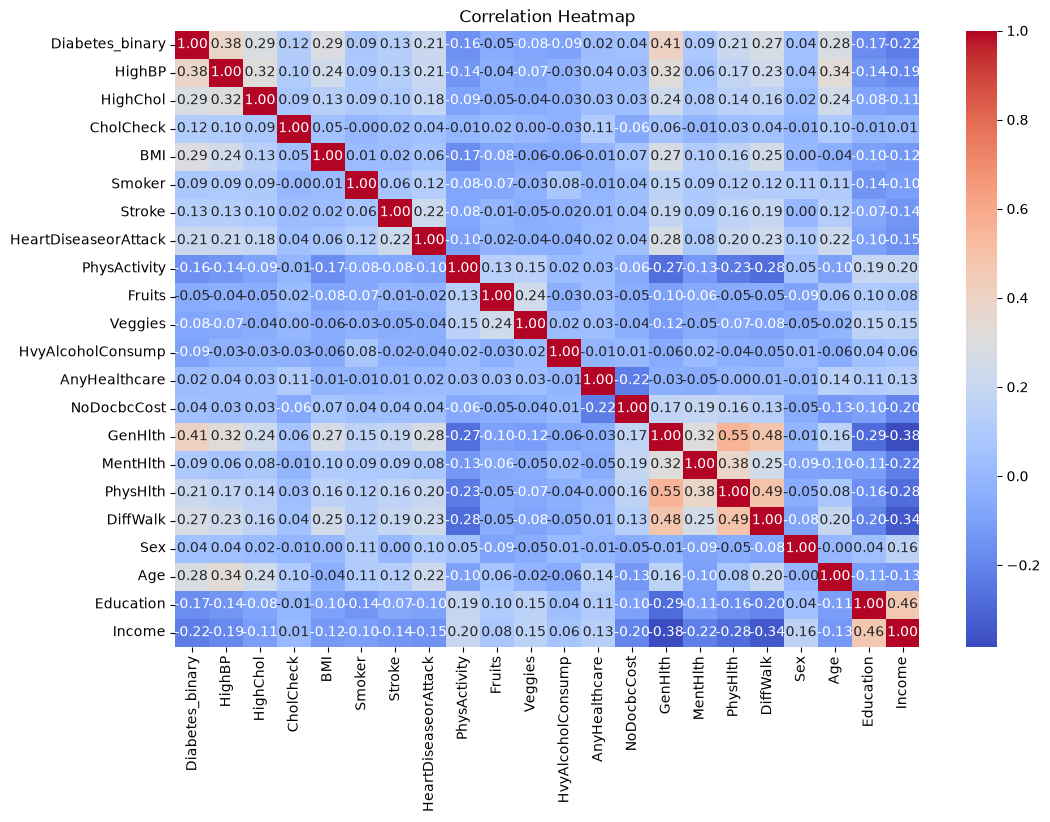

In [5]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [6]:
# 1. Separate features (X) and target (y)
target_column = 'Diabetes_binary'
X = data.drop(target_column, axis=1)
y = data[target_column]
X.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [7]:
y.head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Diabetes_binary, dtype: float64

In [8]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   HighBP                70692 non-null  float64
 1   HighChol              70692 non-null  float64
 2   CholCheck             70692 non-null  float64
 3   BMI                   70692 non-null  float64
 4   Smoker                70692 non-null  float64
 5   Stroke                70692 non-null  float64
 6   HeartDiseaseorAttack  70692 non-null  float64
 7   PhysActivity          70692 non-null  float64
 8   Fruits                70692 non-null  float64
 9   Veggies               70692 non-null  float64
 10  HvyAlcoholConsump     70692 non-null  float64
 11  AnyHealthcare         70692 non-null  float64
 12  NoDocbcCost           70692 non-null  float64
 13  GenHlth               70692 non-null  float64
 14  MentHlth              70692 non-null  float64
 15  PhysHlth              70692 no

In [9]:
variables = X.columns

quantitative_variables = ["BMI", "Age"]
print("len(quantitative_variables): ", len(quantitative_variables))
print(X[quantitative_variables].head())

len(quantitative_variables):  2
    BMI   Age
0  26.0   4.0
1  26.0  12.0
2  26.0  13.0
3  28.0  11.0
4  29.0   8.0


In [10]:
# Already binary encoded categorical variables:
binary_encoded_variables = ["HighBP", "HighChol", 
                            "CholCheck", "Smoker",
                            "Stroke", "HeartDiseaseorAttack",
                            "PhysActivity", "Fruits",
                            "Veggies", "HvyAlcoholConsump",
                            "AnyHealthcare", "NoDocbcCost",
                            "DiffWalk", "Sex"]
print("len(binary_encoded_variables): ", len(binary_encoded_variables))
print(X[binary_encoded_variables].head())

len(binary_encoded_variables):  14
   HighBP  HighChol  CholCheck  Smoker  Stroke  HeartDiseaseorAttack  \
0     1.0       0.0        1.0     0.0     0.0                   0.0   
1     1.0       1.0        1.0     1.0     1.0                   0.0   
2     0.0       0.0        1.0     0.0     0.0                   0.0   
3     1.0       1.0        1.0     1.0     0.0                   0.0   
4     0.0       0.0        1.0     1.0     0.0                   0.0   

   PhysActivity  Fruits  Veggies  HvyAlcoholConsump  AnyHealthcare  \
0           1.0     0.0      1.0                0.0            1.0   
1           0.0     1.0      0.0                0.0            1.0   
2           1.0     1.0      1.0                0.0            1.0   
3           1.0     1.0      1.0                0.0            1.0   
4           1.0     1.0      1.0                0.0            1.0   

   NoDocbcCost  DiffWalk  Sex  
0          0.0       0.0  1.0  
1          0.0       0.0  1.0  
2          0.0 

In [11]:
categorical_variables = [v for v in variables if v not in quantitative_variables and v not in binary_encoded_variables]
print("len(categorical_variables): ", len(categorical_variables))
X[categorical_variables].head()

len(categorical_variables):  5


,GenHlth,MentHlth,PhysHlth,Education,Income
0,3.0,5.0,30.0,6.0,8.0
1,3.0,0.0,0.0,6.0,8.0
2,1.0,0.0,10.0,6.0,8.0
3,3.0,0.0,3.0,6.0,8.0
4,2.0,0.0,0.0,5.0,8.0


In [12]:
# encode categorical variables

X = pd.get_dummies(
    X,
    columns = categorical_variables,
    drop_first = True
)
X.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,Education_4.0,Education_5.0,Education_6.0,Income_2.0,Income_3.0,Income_4.0,Income_5.0,Income_6.0,Income_7.0,Income_8.0
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,False,False,True,False,False,False,False,False,False,True
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,False,False,True,False,False,False,False,False,False,True
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,False,False,True,False,False,False,False,False,False,True
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,False,False,True,False,False,False,False,False,False,True
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,False,True,False,False,False,False,False,False,False,True


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("len(X_train): ", len(X_train))
print("len(X_test): ", len(X_test))
print("ratio: ", (len(X_train)/(len(X_train) + len(X_test))))

len(X_train):  56553
len(X_test):  14139
ratio:  0.7999915124766593


In [14]:
combined_array = np.column_stack((X_test, y_test))
pd.DataFrame(combined_array).to_csv('test_data.csv', index=False)

In [ ]:
# Define the Models Dictionary
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel='linear',probability=True, random_state=42) # probability=True is required for AUC
}

# Loop Through Each Model, Train, Predict, and Print Metrics
for name, model in models.items():
    print(f"\n==================== {name} ====================")
    
    # Train the model
    model.fit(X_train, y_train)

    # Save the model
    joblib.dump(model, f'model/{name}.joblib')
    
    # Generate predictions
    predictions = model.predict(X_test)
    
    # Get probability scores for AUC calculation
    if hasattr(model, "predict_proba"):
        prob_predictions = model.predict_proba(X_test)[:, 1]
    else:
        prob_predictions = model.decision_function(X_test)
        
    # Calculate Metrics
    accuracy = accuracy_score(y_test, predictions)
    auc = roc_auc_score(y_test, prob_predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    mcc = matthews_corrcoef(y_test, predictions)
    
    # Print Metrics
    print(f"Accuracy:                 {accuracy:.4f}")
    print(f"AUC Score:                {auc:.4f}")
    print(f"Precision:                {precision:.4f}")
    print(f"Recall:                   {recall:.4f}")
    print(f"F1 Score:                 {f1:.4f}")
    print(f"Matthews Corr Coeff(MCC): {mcc:.4f}")



==================== Logistic Regression ====================
Accuracy:                 0.7488
AUC Score:                0.8247
Precision:                0.7353
Recall:                   0.7751
F1 Score:                 0.7547
Matthews Corr Coeff(MCC): 0.4984

==================== Decision Tree ====================
Accuracy:                 0.6547
AUC Score:                0.6546
Precision:                0.6523
Recall:                   0.6584
F1 Score:                 0.6553
Matthews Corr Coeff(MCC): 0.3095

==================== KNN ====================
Accuracy:                 0.6894
AUC Score:                0.7469
Precision:                0.6821
Recall:                   0.7062
F1 Score:                 0.6939
Matthews Corr Coeff(MCC): 0.3792

==================== Naive Bayes ====================
Accuracy:                 0.6275
AUC Score:                0.7393
Precision:                0.7223
Recall:                   0.4107
F1 Score:                 0.5237
Matthews Corr Coeff